# Notebook 03 — Análisis Exploratorio (EDA) e Hipótesis

**Maestría en Data Mining · FCEyN UBA · Taller de Tesis I · Grupo G2**

Ejecuta las hipótesis del trabajo sobre los dos datasets:

- **H1** (paradoja de seniority): YearsCodePro vs. target.
- **H2** (DevType): tasa de target=0 por tipo de rol.
- **H4** (Clustering K-Means k=4 + Rogers): segmentación de perfiles.
- **Invarianza estratificada por año**: validación de robustez frente a cambios en el instrumento del survey.

**Lógica:** importada de `scripts/eda.py` y `scripts/invarianza.py`.

## 1. Setup

In [1]:
import sys
import importlib.util
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def load_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod

eda = load_module("eda", ROOT / "scripts" / "eda.py")
inv = load_module("inv", ROOT / "scripts" / "invarianza.py")
pipeline = load_module("pipeline", ROOT / "scripts" / "pipeline.py")

plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print(f"TARGET_LABELS = {eda.TARGET_LABELS}")

TARGET_LABELS = {1: 'Sin discrepancia', 0: 'Con discrepancia uso-actitud'}


## 2. Carga de los dos datasets

In [2]:
df_full = pd.read_parquet(ROOT / "data" / "df_clean.parquet")
df_users = pd.read_parquet(ROOT / "data" / "df_clean_users.parquet")

print(f"Full:    {df_full.shape}  · target=1: {df_full['target'].mean():.1%}")
print(f"Users:   {df_users.shape}  · target=1: {df_users['target'].mean():.1%}")

Full:    (154911, 101)  · target=1: 40.7%
Users:   (80369, 124)  · target=1: 78.5%


## 3. H1 — Paradoja de seniority

Hipótesis: más experiencia profesional → mayor discrepancia (target=0).

Comparamos los resultados sobre **dataset full** vs. **dataset usuarios** para entender cómo la restricción afecta el efecto observado.

### 3.1 H1 sobre dataset USUARIOS (E3 vigente)

In [3]:
tabla_h1_users, r_users, p_users = eda.h1_seniority(df_users.assign(discrepancia=1 - df_users["target"]))
print(f"\nCorrelación punto-biserial: r = {r_users:.4f}, p = {p_users:.2e}\n")
tabla_h1_users

✓ /home/daro-m/Personal/maestria-taller-de-tesis-1/outputs/06_users_H1_seniority.png  (r=0.042, p=1.76e-32)
  global: monotónica ✓  (19.1% → 24.4%, gap = +5.3 pp)
  2023: monotónica ✗  (14.1% → 15.8%, gap = +1.7 pp)
  2024: monotónica ✗  (23.2% → 24.0%, gap = +0.8 pp)
  2025: monotónica ✓  (20.0% → 28.2%, gap = +8.2 pp)

Correlación punto-biserial: r = 0.0418, p = 1.76e-32



,global,2023,2024,2025
exp_tramo,,,,
0–2,19.1,14.1,23.2,20.0
3–5,19.2,14.0,21.9,26.0
6–10,21.2,16.0,23.9,27.6
11–20,23.2,16.1,24.4,27.6
>20,24.4,15.8,24.0,28.2


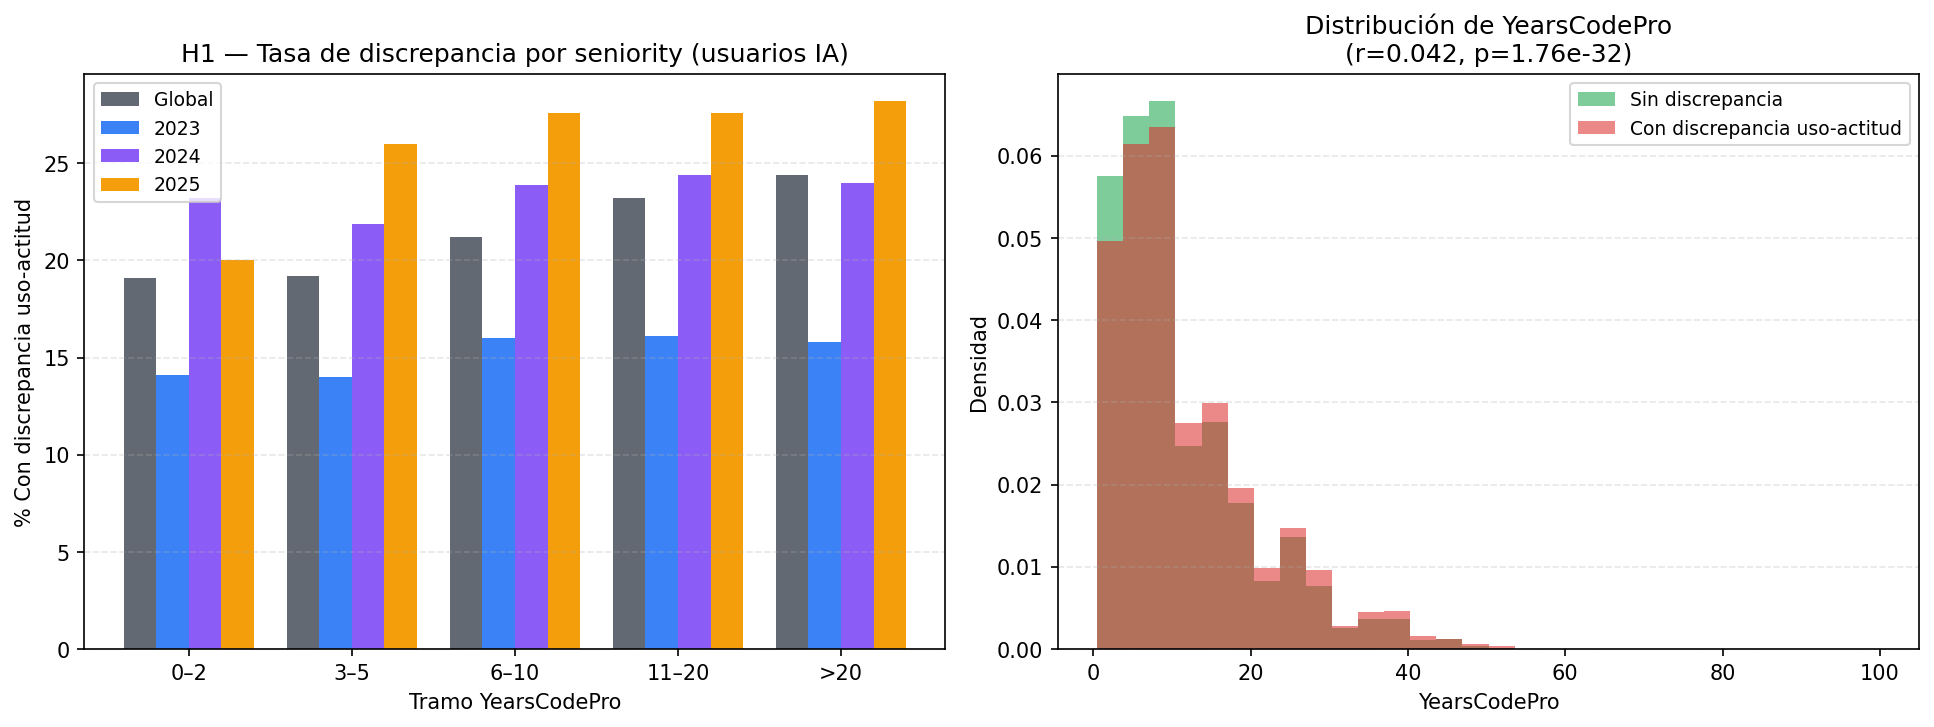

In [4]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "outputs" / "06_users_H1_seniority.png")))

**Lectura.** Sobre usuarios, la correlación entre YearsCodePro y discrepancia es **débil pero significativa** (r = 0,042). El gap junior–senior es de ~5 pp globalmente, mucho menor que el observado sobre el dataset completo (~22 pp en 2023). Esto confirma que la paradoja de seniority estaba mayormente impulsada por la separación usuarios/no-usuarios.

### 3.2 H1 estratificado por año (sobre dataset FULL — defensa de invarianza)

In [5]:
df_inv = df_full.assign(resist=1 - df_full["target"])
tabla_h1_strat, _ = inv.analisis_h1(df_inv)
tabla_h1_strat

  global: monotónica creciente = ✗ (49.3% → 64.4%)
  2023: monotónica creciente = ✓ (51.7% → 74.6%)
  2024: monotónica creciente = ✓ (46.4% → 63.2%)
  2025: monotónica creciente = ✗ (55.8% → 56.4%)


,global,2023,2024,2025
exp_tramo,,,,
0–2,49.3,51.7,46.4,55.8
3–5,53.7,58.3,47.6,55.2
6–10,61.5,60.6,57.9,68.1
11–20,60.7,68.0,58.0,54.0
>20,64.4,74.6,63.2,56.4


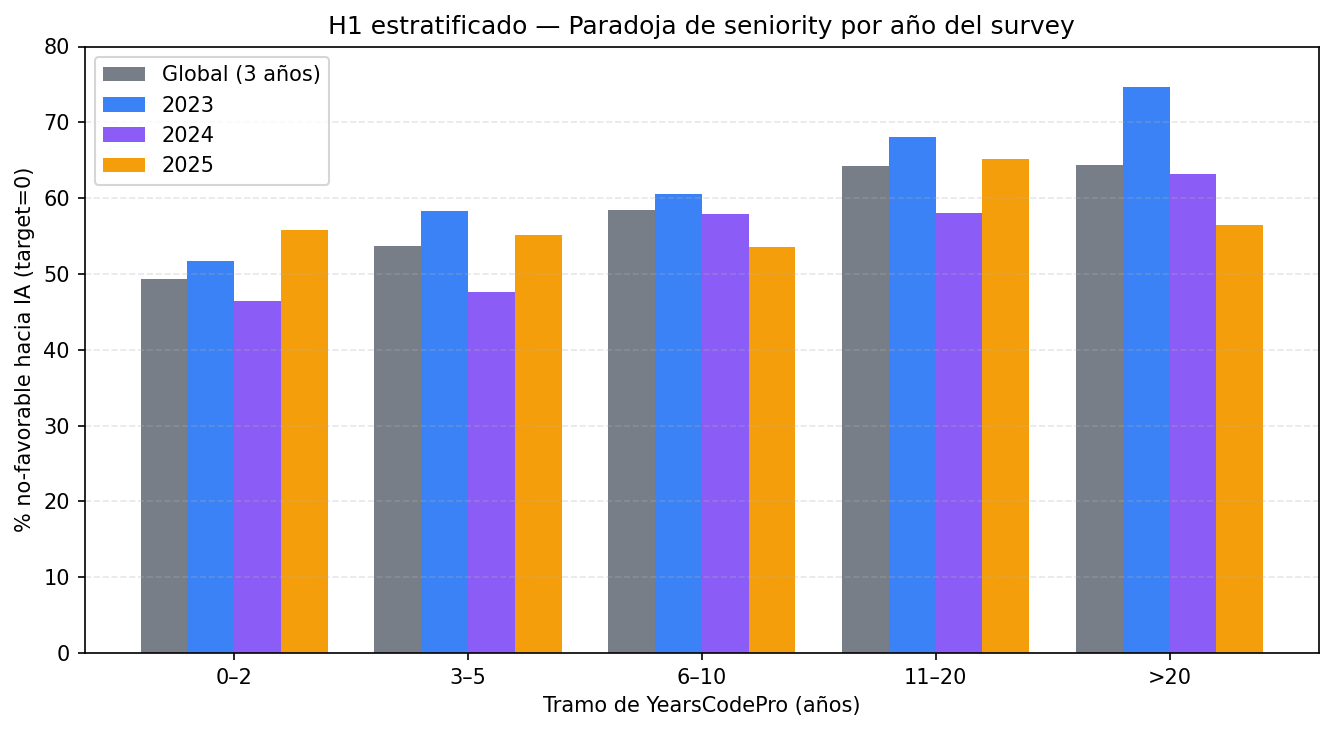

In [6]:
display(Image(filename=str(ROOT / "outputs" / "05_invarianza_H1_seniority.png")))

**Lectura.** El gap junior–senior **se debilita temporalmente**:
- 2023: +22,9 pp (paradoja muy marcada)
- 2025: +0,6 pp (gradiente casi plano)

La dirección se preserva en los 3 años, pero la magnitud cae. Coherente con el mecanismo de Lee & See (2004): la exposición creciente recalibra a todos los segmentos, achatando el gradiente.

## 4. H2 — Discrepancia por DevType

### 4.1 H2 sobre dataset USUARIOS

In [7]:
df_h2, tasa_global = eda.h2_devtype(df_users.assign(discrepancia=1 - df_users["target"]))
print(f"Tasa global discrepancia: {tasa_global:.1f}%\n")
df_h2.head(10).round(1)

✓ /home/daro-m/Personal/maestria-taller-de-tesis-1/outputs/06_users_H2_devtype.png
Tasa global discrepancia: 21.5%



,devtype,tasa,n
1,Data scientist or machine learning specialist,16.1,2143
5,"Developer, front-end",18.4,5641
8,Engineering manager,18.5,1765
7,"Developer, mobile",20.3,3115
9,Other,20.5,13404
6,"Developer, full-stack",20.9,30281
2,"Developer, back-end",23.2,14981
0,"Architect, software or solutions",24.6,1503
10,Other (please specify):,25.0,1595
3,"Developer, desktop or enterprise applications",26.1,2997


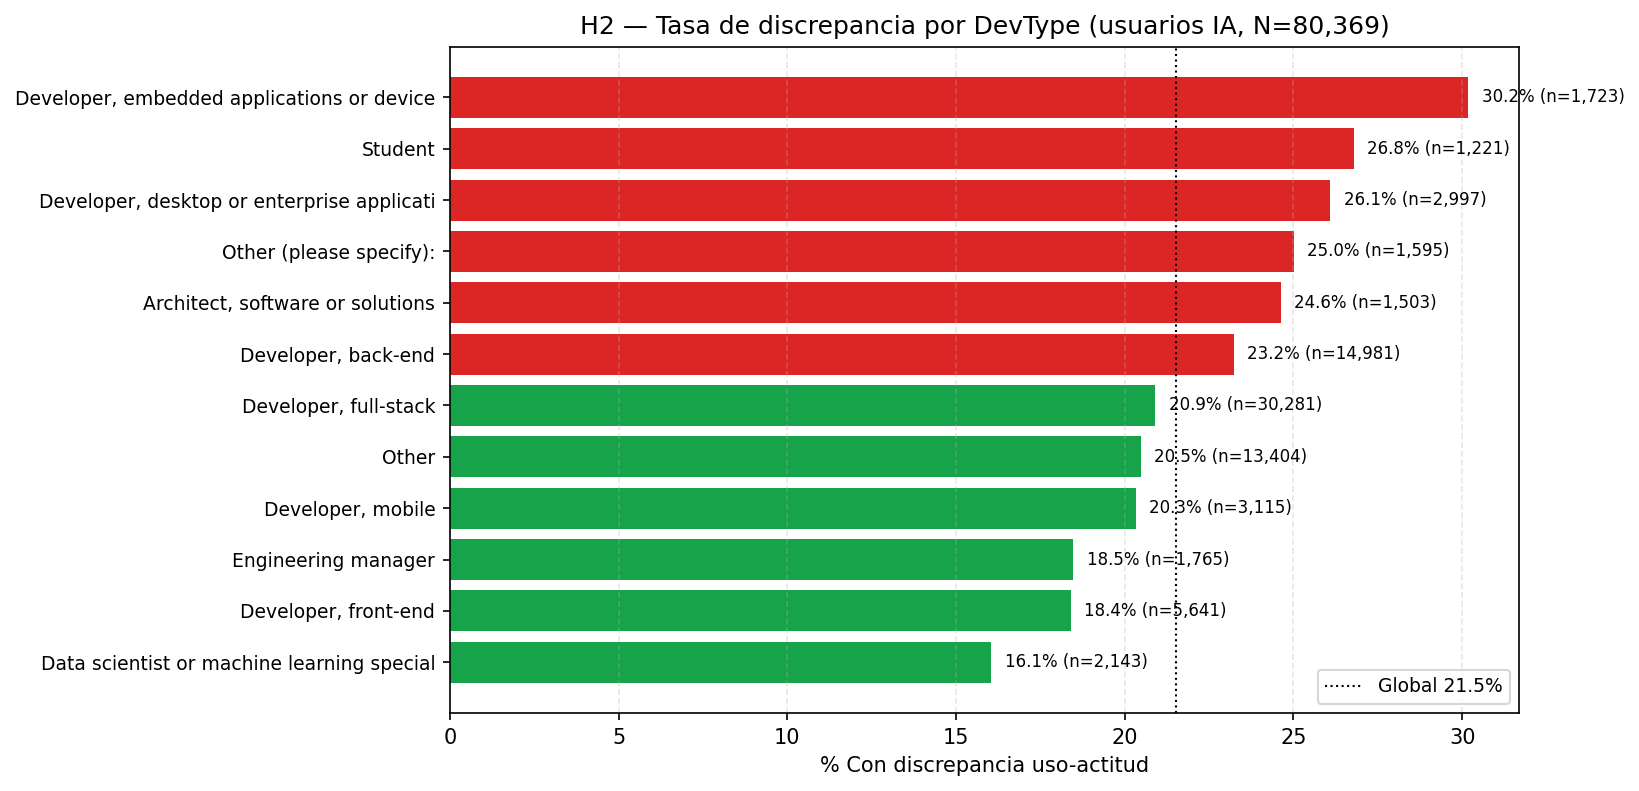

In [8]:
display(Image(filename=str(ROOT / "outputs" / "06_users_H2_devtype.png")))

**Lectura.** Embedded (30,2 %), Student (26,8 %), Desktop (26,1 %) ocupan los puestos más altos de discrepancia. Data Scientist / ML el más bajo. Mismo orden relativo que sobre el dataset completo (E2), aunque con magnitudes ~40 % menores.

### 4.2 H2 estratificado por año

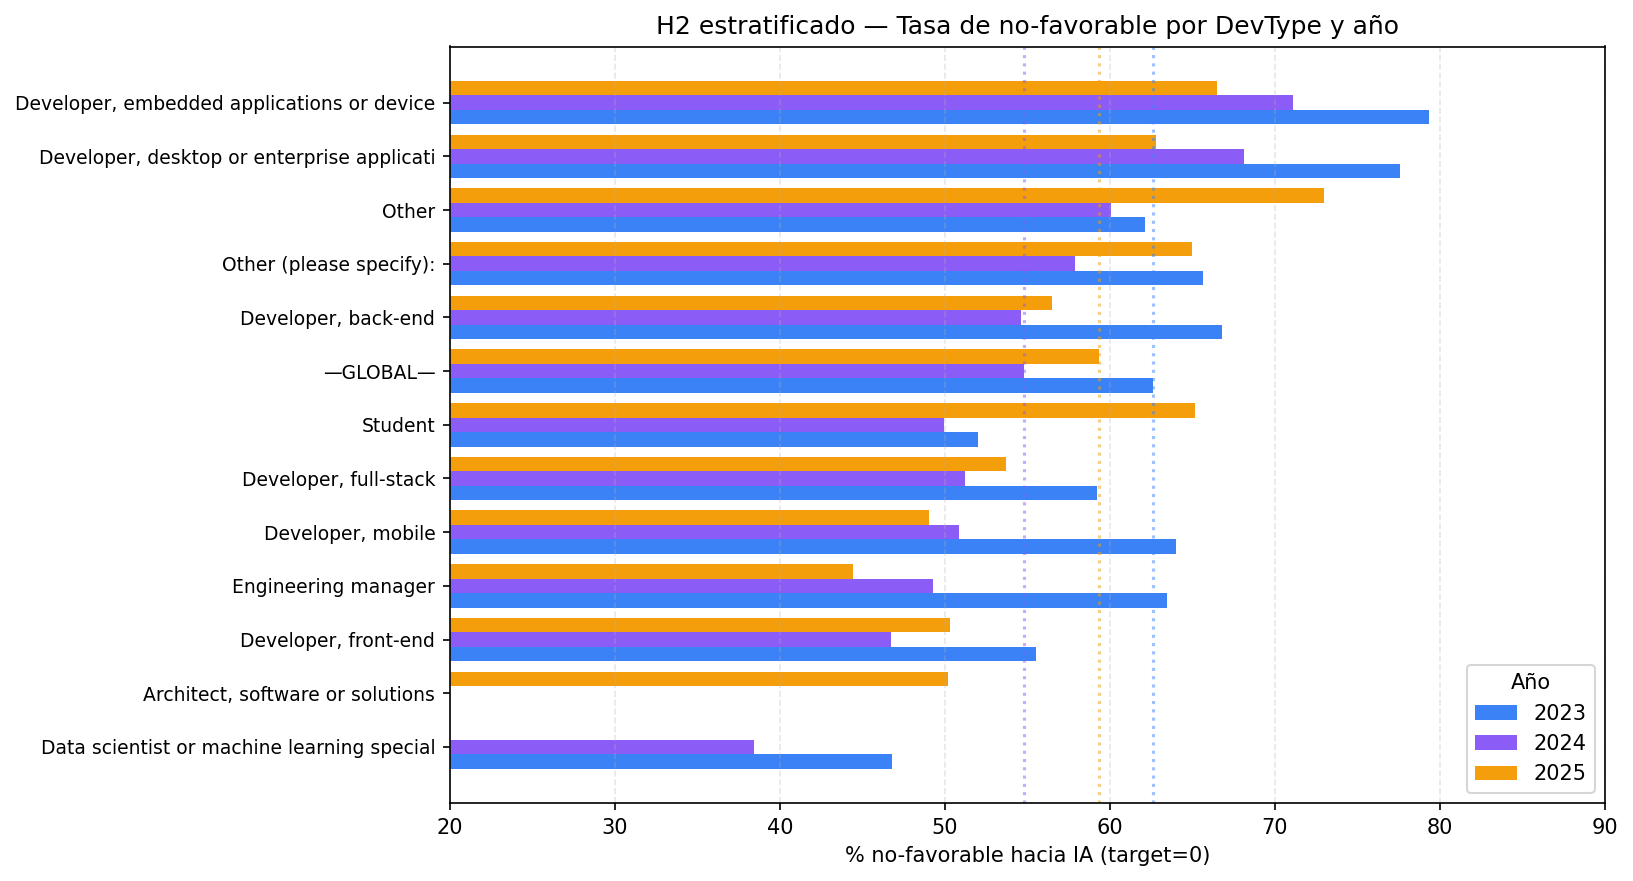

In [9]:
tabla_h2_strat, _ = inv.analisis_h2(df_inv)
display(Image(filename=str(ROOT / "outputs" / "05_invarianza_H2_devtype.png")))

**Lectura.** El orden relativo de DevTypes se mantiene estable en los 3 años. Magnitudes convergen — mismo achatamiento que en H1. **No es artefacto del cambio de instrumento.**

## 5. H4 — Segmentación K-Means k=4 + tipología Rogers

### 5.1 H4 sobre dataset USUARIOS

In [10]:
df_clust_users, tabla_h4_users = eda.h4_clusters(df_users.assign(discrepancia=1 - df_users["target"]))
tabla_h4_users

  Clustering features: ['YearsCodePro', 'YearsCode', 'WorkExp', 'EdLevel', 'OrgSize', 'lang_count', 'db_count', 'plat_count', 'env_count']


✓ /home/daro-m/Personal/maestria-taller-de-tesis-1/outputs/06_users_H4_clusters.png


,% observado,% teórico (Rogers),% discrepancia,Exp. mediana
Early Adopters,48.7,13.5,20.6,7.0
Early Majority,16.1,34.0,21.6,8.0
Late Majority,17.6,34.0,21.9,9.0
Laggards,17.6,16.0,23.6,25.0


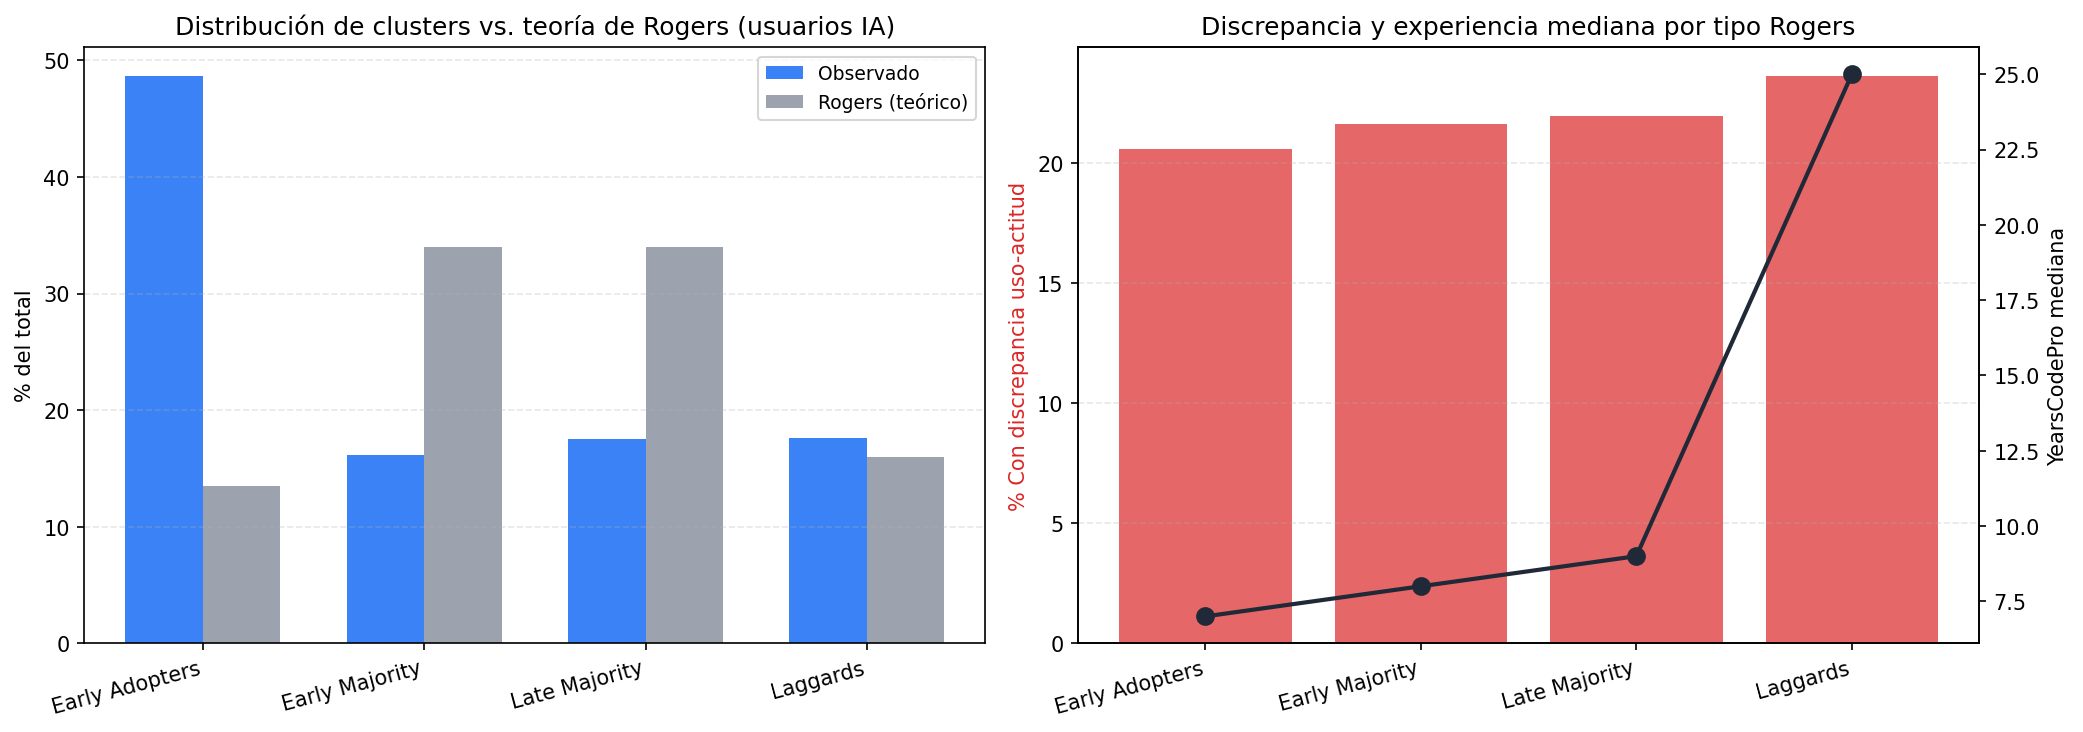

In [11]:
display(Image(filename=str(ROOT / "outputs" / "06_users_H4_clusters.png")))

**Lectura clave.** **Rogers NO replica sobre usuarios** — Early Adopters 48,7 % observado vs. 13,5 % teórico. Es esperable: ya filtramos a los que adoptaron. Rogers pasa de validación externa a **segmentación interna informativa**.

## 6. Análisis de feature importance estratificado por año

Entrena Random Forest **por separado** sobre cada año y compara importancias.

In [12]:
tabla_fi, _, ranks = inv.analisis_feature_importance(df_inv)
print("Top 15 features por importancia promedio (3 años):")
tabla_fi.head(15).round(4)

Top 15 features por importancia promedio (3 años):


,2023,2024,2025,promedio
env_Visual_Studio_Code,0.0606,0.0816,0.0941,0.0787
YearsCode,0.1157,0.0847,0.0108,0.0704
env_count,0.0192,0.0435,0.1465,0.0697
plat_count,0.0750,0.0772,0.0522,0.0681
lang_count,0.0189,0.0338,0.0997,0.0508
Region_NA,0.0063,0.0292,0.1151,0.0502
YearsCodePro,0.0645,0.0593,0.0107,0.0448
db_count,0.0235,0.0336,0.0650,0.0407
plat_Vercel,0.0504,0.0302,0.0031,0.0279
lang_TypeScript,0.0403,0.0201,0.0226,0.0277


In [13]:
print("Ranks por año (top 15) — rank_max_diff = estabilidad inter-anual:")
ranks.head(15)

Ranks por año (top 15) — rank_max_diff = estabilidad inter-anual:


,2023,2024,2025,rank_max_diff
env_Visual_Studio_Code,4,2,4,2
YearsCode,1,1,17,16
env_count,12,5,1,11
plat_count,2,3,6,4
lang_count,13,6,3,10
Region_NA,36,9,2,34
YearsCodePro,3,4,18,15
db_count,11,7,5,6
plat_Vercel,5,8,40,35
lang_TypeScript,7,12,10,5


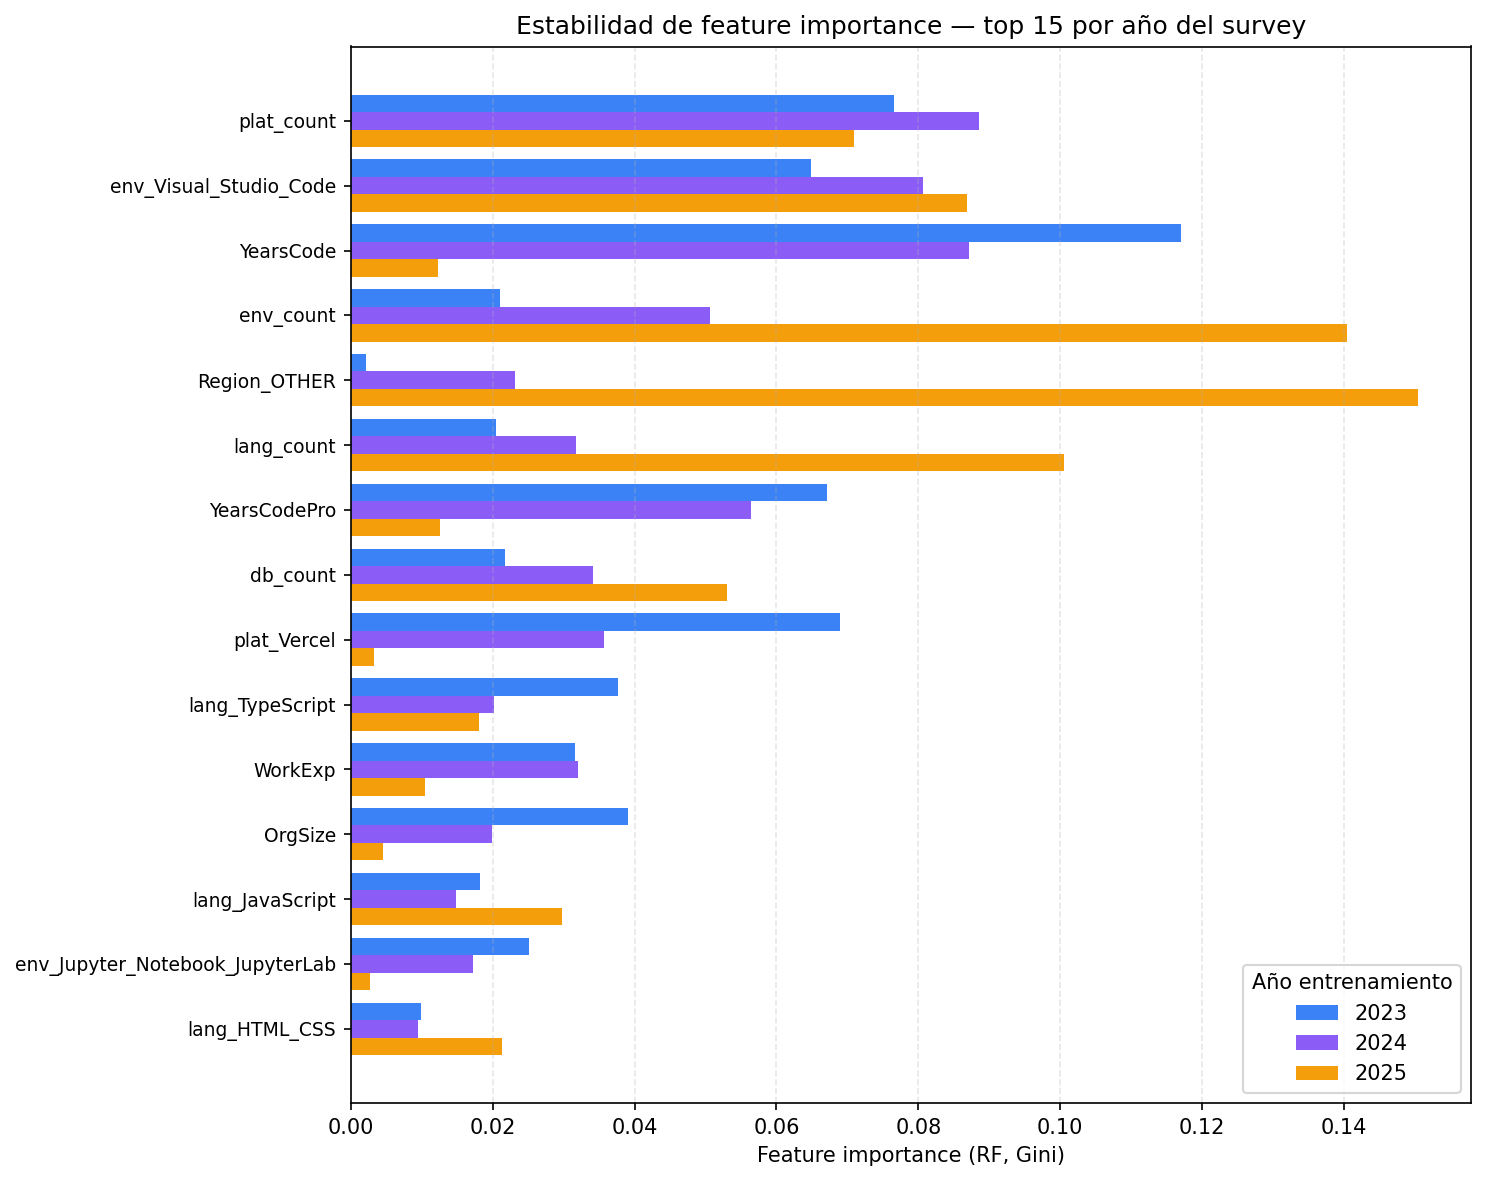

In [14]:
display(Image(filename=str(ROOT / "outputs" / "05_invarianza_feature_importance.png")))

**Lectura.**
- Stack técnico (`plat_count`, `env_Visual_Studio_Code`, `env_count`) es **estable top-5 en los 3 años**.
- `YearsCode` y `YearsCodePro` **pierden importancia** entre 2023 (rank 1) y 2025 (rank ~16) — coherente con H1 debilitándose.
- `Region_OTHER` salta de rank 78 a rank 1 entre 2023 y 2025 — investigar.

## 7. H5 — Brecha uso–confianza individual (Lee & See, sobre dataset FULL)

H5 requiere ambas dimensiones (uso × confianza) y por lo tanto solo se calcula sobre el dataset full (en usuarios colapsa a 2 cuadrantes).

In [15]:
df23 = pd.read_csv(ROOT / "data" / "2023" / "survey_results_public.csv", low_memory=False, usecols=["AISelect", "AISent", "MainBranch"])
df24 = pd.read_csv(ROOT / "data" / "2024" / "survey_results_public.csv", low_memory=False, usecols=["AISelect", "AISent", "MainBranch"])
df25 = pd.read_csv(ROOT / "data" / "2025" / "survey_results_public.csv", low_memory=False, usecols=["AISelect", "AISent", "MainBranch"])

# Aplanar AISelect 2025
aiselect_yes_2025 = ["Yes, I use AI tools daily", "Yes, I use AI tools weekly", "Yes, I use AI tools monthly or infrequently"]
df25["AISelect"] = df25["AISelect"].apply(lambda v: "Yes" if v in aiselect_yes_2025 else v)

df23["survey_year"] = 2023
df24["survey_year"] = 2024
df25["survey_year"] = 2025
h5 = pd.concat([df23, df24, df25], ignore_index=True)
h5 = h5[(h5["MainBranch"] == "I am a developer by profession") & h5["AISelect"].notna() & h5["AISent"].notna()].copy()

def cuadrante(row):
    usa = row["AISelect"] == "Yes"
    confia = row["AISent"] in ["Favorable", "Very favorable"]
    if usa and confia:
        return "Calibrado+ (usa y confía)"
    if usa and not confia:
        return "Subconfianza (usa pero no confía)"
    if not usa and confia:
        return "Sobreconfianza (no usa pero confía)"
    return "Calibrado− (no usa y no confía)"

h5["cuadrante"] = h5.apply(cuadrante, axis=1)
print(f"N (con AISelect+AISent no nulos): {len(h5):,}\n")
print("Distribución global de los 4 cuadrantes:")
print((h5["cuadrante"].value_counts(normalize=True) * 100).round(1))

N (con AISelect+AISent no nulos): 108,508

Distribución global de los 4 cuadrantes:
cuadrante
Calibrado+ (usa y confía)              58.1
Subconfianza (usa pero no confía)      15.6
Calibrado− (no usa y no confía)        13.2
Sobreconfianza (no usa pero confía)    13.1
Name: proportion, dtype: float64


In [16]:
print("\nEvolución temporal:")
print((h5.groupby("survey_year")["cuadrante"].value_counts(normalize=True) * 100).unstack().round(1))


Evolución temporal:
cuadrante    Calibrado+ (usa y confía)  Calibrado− (no usa y no confía)  \
survey_year                                                               
2023                              53.6                             14.3   
2024                              63.5                              8.9   
2025                              59.0                             17.0   

cuadrante    Sobreconfianza (no usa pero confía)  \
survey_year                                        
2023                                        22.5   
2024                                         8.5   
2025                                         2.2   

cuadrante    Subconfianza (usa pero no confía)  
survey_year                                     
2023                                       9.6  
2024                                      19.2  
2025                                      21.8  


**Lectura.**
- **Subconfianza entre usuarios** crece monotónicamente: 15 % (2023) → 27 % (2025) — refuerza la idea de recalibración.
- **Sobreconfianza entre no-usuarios** colapsa: 61 % (2023) → 12 % (2025) — la mayoría ya tuvo exposición.
- Calibrado+ se mantiene como mayoría (~58 % global), pero los flujos internos muestran la dinámica de Lee & See operando intra-dataset.

## 8. Próximo paso

`notebooks/04_modelado.ipynb` — Modelado supervisado (4 modelos + CV + SHAP) sobre dataset usuarios y comparativa E2 vs E3.